In [1]:
import shutil
import sys

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
print()

# OS 패키지 확인 (pip로 설치되지 않는 것들)
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "✗ 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치 — Path 확인 후 재시작")
print()

# 파이썬 패키지 확인
for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:14s}: OK")
    except ImportError:
        print(f"{mod:14s}: ✗ 미설치")

Python: 3.11.9
가상환경 경로: c:\workspaces\multimodal-rag\.venv
가상환경 안에서 실행 중? True

Poppler  : OK
Tesseract: OK

langchain     : OK
unstructured  : OK
chromadb      : OK
tiktoken      : OK
PIL           : OK


In [2]:
import os
import time
import pickle
import base64
import tiktoken
import uuid
import re
from pathlib import Path
from dotenv import load_dotenv
from openai import OpenAI, AuthenticationError
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.messages import HumanMessage
from langchain_core.documents import Document as _Doc
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
from langchain_core.stores import InMemoryStore
from langchain_text_splitters import CharacterTextSplitter
from langchain_classic.retrievers.multi_vector import MultiVectorRetriever
from langchain_openai import ChatOpenAI
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma
from unstructured.partition.pdf import partition_pdf
from collections import Counter
from IPython.display import Image, display

print("임포트 완료")

임포트 완료


In [3]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

fname = "invest.pdf"
pdf_dir = Path("../data")
pdf_path = pdf_dir / fname

fpath = str(pdf_dir) + os.sep

print("현재 위치 : " , Path.cwd())
print("프로젝트 루트:", PROJECT_ROOT)
print("PDF 폴더     :", pdf_dir, pdf_path.resolve())
print("PDF 존재 여부:", pdf_path.exists())

현재 위치 :  c:\workspaces\multimodal-rag\notebooks
프로젝트 루트: c:\workspaces\multimodal-rag
PDF 폴더     : ..\data C:\workspaces\multimodal-rag\data\invest.pdf
PDF 존재 여부: True


In [4]:
load_dotenv(PROJECT_ROOT / ".env")

try:
    openai_api_key = os.environ["OPENAI_API_KEY"]
    if not openai_api_key.strip():
        raise ValueError("OPENAI_API_KEY 값이 비어 있습니다. .env 파일을 확인하세요.")
    else:
        print("환경변수 OPENAI_API_KEY 로드 완료")
except KeyError:
    raise ValueError("환경변수 OPENAI_API_KEY 키가 없습니다. .env 파일을 확인하세요.")

환경변수 OPENAI_API_KEY 로드 완료


In [5]:
try:
    OpenAI(api_key=openai_api_key).models.list()
    print("Good")
except AuthenticationError:
    raise ValueError("환경변수 OPENAI_API_KEY 가 없습니다. .env 파일을 확인하세요.")

Good


In [6]:
def extract_pdf_elements(path, fname):
    """
    PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출합니다.

    path : 파일 경로 (추출된 이미지 파일이 저장될 위치)
    fname: 파일 이름
    """
    return partition_pdf(
        filename=path + fname,
        strategy="hi_res",
        extract_images_in_pdf=True,
        infer_table_structure=True,
        chunking_strategy="by_title",
        max_characters=4000,
        new_after_n_chars=3800,
        combine_text_under_n_chars=2000,
        extract_image_block_output_dir=path+"figures",
    )


print("extract_pdf_elements 정의 완료")

extract_pdf_elements 정의 완료


In [7]:
def categorize_elements(raw_pdf_elements):
    """
    PDF에서 추출한 요소들을 테이블과 텍스트로 분류합니다.

    raw_pdf_elements: unstructured.documents.elements 리스트
    """
    tables = []
    texts = []

    for element in raw_pdf_elements:
        if "unstructured.documents.elements.Table" in str(type(element)):
            tables.append(str(element))
        elif "unstructured.documents.elements.CompositeElement" in str(type(element)):
            texts.append(str(element))

    return texts, tables


print("categorize_elements 정의 완료")

categorize_elements 정의 완료


In [8]:
start = time.time()

raw_pdf_elements = extract_pdf_elements(fpath, fname)

print(f"추출 완료 — {time.time() - start:.1f}초 소요")
print("추출된 전체 요소 수:", len(raw_pdf_elements))

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1
No languages specified, defaulting to English.
Loading weights: 100%|██████████| 367/367 [00:00<00:00, 3114.67it/s]


추출 완료 — 99.9초 소요
추출된 전체 요소 수: 17


In [9]:
texts, tables = categorize_elements(raw_pdf_elements)

print("텍스트 블록 수:", len(texts))
print("표 블록 수    :", len(tables))

텍스트 블록 수: 12
표 블록 수    : 5


In [10]:
counts = Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements)

for element_type, count in counts.most_common():
    print(f"{element_type:22s}: {count}개")

CompositeElement      : 12개
Table                 : 5개


In [11]:
figures_dir = Path(fpath) / "figures"

if figures_dir.exists():
    image_files = sorted(
        f for f in figures_dir.iterdir()
        if f.suffix.lower() in (".jpg", ".jpeg", ".png")
    )
    print(f"추출된 이미지: {len(image_files)}개\n")
    for f in image_files[:10]:
        print(f"  {f.name}  ({f.stat().st_size // 1024} KB)")
else:
    print("X figures 폴더가 없습니다.")

추출된 이미지: 41개

  figure-1-1.jpg  (12 KB)
  figure-1-2.jpg  (26 KB)
  figure-10-20.jpg  (65 KB)
  figure-10-21.jpg  (51 KB)
  figure-10-22.jpg  (48 KB)
  figure-11-23.jpg  (36 KB)
  figure-11-24.jpg  (64 KB)
  figure-12-25.jpg  (55 KB)
  figure-12-26.jpg  (73 KB)
  figure-12-27.jpg  (36 KB)


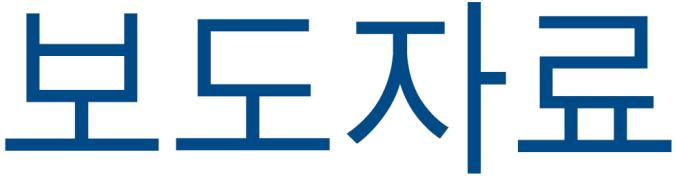

In [12]:
if figures_dir.exists() and image_files:
    display(Image(filename=str(image_files[0]), width=500))
else:
    print("표시할 이미지가 없습니다.")

In [13]:
text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=2000,       # 각 텍스트 블록의 최대 크기
    chunk_overlap=200,    # TODO 8: 청크 간 겹칠 글자 수
)

joined_texts = " ".join(texts)
texts_2k_token = text_splitter.split_text(joined_texts)

print("원본 블록 수  :", len(texts))
print("분할 후 블록 수:", len(texts_2k_token))
print("전체 글자 수  :", len(joined_texts))

원본 블록 수  : 12
분할 후 블록 수: 18
전체 글자 수  : 20404


In [14]:
print("=" * 60)
print("[원본 texts[0]] 앞 300자")
print("=" * 60)
print(texts[0][:300])
print()

print("=" * 60)
print("[분할 texts_2k_token[0]] 앞 300자")
print("=" * 60)
print(texts_2k_token[0][:300])

[원본 texts[0]] 앞 300자
2026년 10월 22일 공보 2026-10-17호

HOE

이 자료는 배포시부터 취급하여 주십시오.

제 목 : 경제상황 평가(2026년 10월)

□ 국내경제는 중동지역 불확실성 확대에도 반도체 경기의 강한 호조세와 여타부문으로의 파급 확산 등으로 기존 전망경로를 상회하는 높은 성장세 전망

□ 물가상승률은 누적된 비용압력이 전이되고 수요압력도 점차 확대됨에 따라 높은 수준 지속 예상

□ 전망경로에는 반도체 경기, 중동상황 등과 관련한 불확실성이 큰 상황

※ 자세한 내용은 <붙 임> 경제상황 평가(2026년 10월) 참조


[분할 texts_2k_token[0]] 앞 300자
2026년 10월 22일 공보 2026-10-17호

HOE

이 자료는 배포시부터 취급하여 주십시오.

제 목 : 경제상황 평가(2026년 10월)

□ 국내경제는 중동지역 불확실성 확대에도 반도체 경기의 강한 호조세와 여타부문으로의 파급 확산 등으로 기존 전망경로를 상회하는 높은 성장세 전망

□ 물가상승률은 누적된 비용압력이 전이되고 수요압력도 점차 확대됨에 따라 높은 수준 지속 예상

□ 전망경로에는 반도체 경기, 중동상황 등과 관련한 불확실성이 큰 상황

※ 자세한 내용은 <붙 임> 경제상황 평가(2026년 10월) 참조



In [15]:
def generate_text_summaries(texts, tables, summarize_texts=False):
    prompt_text = """표와 텍스트를 검색용으로 요약하는 도우미 / 임베딩되어 원본 검색에 쓰임 / 
                        검색에 최적화된 간결한 요약 작성 / 요약할 표 또는 텍스트: {element}"""
    prompt = ChatPromptTemplate.from_template(prompt_text)
    model = ChatOpenAI(temperature=0, model="gpt-4o-mini")

    summarize_chain = {"element": lambda x: x} | prompt | model | StrOutputParser()

    text_summaries = []
    table_summaries = []
    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, {"max_concurrency": 5})
    elif texts:
        text_summaries = texts

    if tables:
        table_summaries = summarize_chain.batch(tables, {"max_concurrency": 5})

    return text_summaries, table_summaries

print("generate_text_summaries 정의 완료")

generate_text_summaries 정의 완료


In [16]:
start = time.time()

text_summaries, table_summaries = generate_text_summaries(texts_2k_token, tables, summarize_texts=True)

print(f"소요 시간: {time.time() - start:.1f}초")
print(f"텍스트 요약 수: {len(text_summaries)}")
print(f"표 요약 수: {len(table_summaries)}")

소요 시간: 27.5초
텍스트 요약 수: 18
표 요약 수: 5


In [17]:
print("="*60)
print("[원본]texts_2k_token[0] 의 앞 300자")
print("="*60)
print(texts_2k_token[0][:300])
print()
print("="*60)
print("[요약본]text_summaries[0] 전체")
print("="*60)
print(text_summaries[0])
print()
print(f"원본 글자 수: {len(texts_2k_token[0])}")
print(f"요약 글자 수: {len(text_summaries[0])}")
print(f"압축률(%): {(len(text_summaries[0])/len(texts_2k_token[0]))*100}%")

[원본]texts_2k_token[0] 의 앞 300자
2026년 10월 22일 공보 2026-10-17호

HOE

이 자료는 배포시부터 취급하여 주십시오.

제 목 : 경제상황 평가(2026년 10월)

□ 국내경제는 중동지역 불확실성 확대에도 반도체 경기의 강한 호조세와 여타부문으로의 파급 확산 등으로 기존 전망경로를 상회하는 높은 성장세 전망

□ 물가상승률은 누적된 비용압력이 전이되고 수요압력도 점차 확대됨에 따라 높은 수준 지속 예상

□ 전망경로에는 반도체 경기, 중동상황 등과 관련한 불확실성이 큰 상황

※ 자세한 내용은 <붙 임> 경제상황 평가(2026년 10월) 참조


[요약본]text_summaries[0] 전체
**경제상황 평가 요약 (2026년 10월)**

- **국내경제 전망**: 중동지역의 불확실성에도 불구하고 반도체 경기 호조와 다른 부문으로의 긍정적 파급 효과로 인해 높은 성장세가 예상됨.
  
- **물가상승률**: 누적된 비용 압력과 확대되는 수요 압력으로 인해 물가상승률이 높은 수준을 지속할 것으로 보임.

- **불확실성 요인**: 반도체 경기와 중동 상황 등 여러 불확실성이 전망에 영향을 미칠 가능성이 있음.

- **세계경제 동향**: 높은 에너지 가격에도 불구하고 AI 투자 증가로 양호한 성장세 지속. 세계교역은 지정학적 리스크와 통상 갈등으로 제약받지만 AI 관련 교역은 증가할 전망.

- **국제유가**: 중동 상황에 따라 단기적으로 변동성이 클 것으로 예상되나, 중장기적으로는 공급 증가로 하락할 가능성이 있음.

- **반도체 경기**: AI 확산과 인프라 투자 덕분에 견조한 흐름을 유지하나, 수익화 및 투자 속도에 대한 불확실성은 여전히 존재.

**문의처**: 한국은행 조사국 경제모형실, 전화 02-759-4016, 4135.  
**자세한 내용**: 한국은행 웹사이트(http://www.bok.or.kr) 참조.

원본 글자 수: 1194
요약 글자 수: 589
압축률(%): 49.329983249581

In [18]:
if table_summaries:
    for i, (table, summary) in enumerate(zip(tables[:3], table_summaries[:3])):
        print("="*60)
        print(f"[원본 {i+1} (앞 300자)]")
        print("="*60)
        print(table[:300])
        print()
        print("="*60)
        print(f"[요약본 {i+1}]")
        print("="*60)
        print(summary)
        print()
else:
    print("표 요약이 비어 있습니다.")

[원본 1 (앞 300자)]
경제성장 : 조사총괄팀 차 장 이종웅 (02-759-4202), 과 장 최영우 (4167), 조사역 추성윤 (4172) 세계경제 : 국제종합팀 차 장 김보희 (4280) 경상수지 : 국제무역팀 차 장 남석모 (4190) 가 : 물가동향팀 과 장 원영진 (4220) 고용·임금 : 고용동향팀 과 장 선진산 (4205) 경제모형 : 모형전망팀 과 장 박병국 (4137)

[요약본 1]
**경제 관련 연락처 요약**

1. **경제성장**  
   - 조사총괄팀  
     - 차장: 이종웅 (02-759-4202)  
     - 과장: 최영우 (4167)  
     - 조사역: 추성윤 (4172)  

2. **세계경제**  
   - 국제종합팀  
     - 차장: 김보희 (4280)  

3. **경상수지**  
   - 국제무역팀  
     - 차장: 남석모 (4190)  

4. **물가**  
   - 물가동향팀  
     - 과장: 원영진 (4220)  

5. **고용·임금**  
   - 고용동향팀  
     - 과장: 선진산 (4205)  

6. **경제모형**  
   - 모형전망팀  
     - 과장: 박병국 (4137)  

[원본 2 (앞 300자)]
(전기대비, %) 2024 연간 4/4 1/4 2/4 3/4 7월 8월 9월 GDP성장률1) 3.0 2.3 0.2 2.5 2.2 .. - - 산업생산2) -0.7 1.1 -0.5 0.3 1.2 0.7 0.2 0.1 미 소매판매 1.5 3.2 0.6 0.8 2.8 1.2 -0.4 1.3 국 소비자물가3) 2.9 2.6 2.7 2.7 3.9 3.5 3.4 3.4 비농업취업자수 증감(천명) 1,826 764 -91 130 291 130 -10 133 GDP성장률 1.3 1.2 0.2 0.0 0.6 .. - - 산업생산2) -3.0 1.8

[요약본 2]
### 2024년 경제 지표 요약

- **GDP 성장률**: 
  - 1분기: 3.0%, 2분기: 2.3

In [19]:
def encode_image(image_path):
    with open(image_path, "rb") as img_file:
        return base64.b64encode(img_file.read()).decode("UTF-8")

img_files = sorted( # 3. 이름순으로 정렬해서 리스트로 반환하겠다.
    f for f in figures_dir.iterdir() # 1. 폴더 안의 항목들을 하나씩 꺼내
    if f.suffix.lower() in (".jpg", ".jpeg", ".png") # 2. 확장자가 이미지인 것만
)
sample_b64 = encode_image(img_files[0])

print(f"원본 파일: {img_files[0].name}")
print(f"문자열 길이: {len(sample_b64)}자")
print(f"앞 100자: {sample_b64[:100]}")

원본 파일: figure-1-1.jpg
문자열 길이: 17620자
앞 100자: /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


In [20]:
def image_summarize(img_base64, prompt):
    chat = ChatOpenAI(model="gpt-4o-mini", max_tokens=1024)
    msg = chat.invoke([
        HumanMessage(content=[
            {"type": "text", "text": prompt},
            {"type": "image_url", "image_url": {"url": f"data:image/jpg;base64,{img_base64}"},
             },
        ])
    ])

    return msg.content

test_prompt = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul)."""

print(image_summarize(sample_b64, test_prompt))

보도자료 텍스트 이미지, 파란색 글씨로 "보도자료"라고 적혀 있음.


In [21]:
def generate_img_summaries(path):
    img_base64_list = []
    img_summaries = []
    prompt_kor = """당신은 검색을 위해 이미지를 요약하는 어시스턴트입니다.
    이 요약문은 임베딩되어 원본 이미지를 검색하는 데 사용됩니다.
    검색에 최적화된 간결한 이미지 요약을 작성하세요."""

    for img_file in sorted(os.listdir(path)):
        if img_file.endswith((".jpg", ".jpeg", ".png")):
            img_path = os.path.join(path, img_file)
            b64_img = encode_image(img_path)
            img_base64_list.append(b64_img)
            img_summaries.append(image_summarize(b64_img, prompt_kor))

    return img_base64_list, img_summaries

print("이미지 요약 정의 완료")

이미지 요약 정의 완료


In [22]:
start = time.time()

img_base64_list, img_summaries = generate_img_summaries(str(figures_dir))

print(f"소요 시간: {time.time() - start:.1f}초")
print(f"요약된 이미지 수: {len(img_summaries)}")

소요 시간: 97.4초
요약된 이미지 수: 41


[1] figure-1-1.jpg


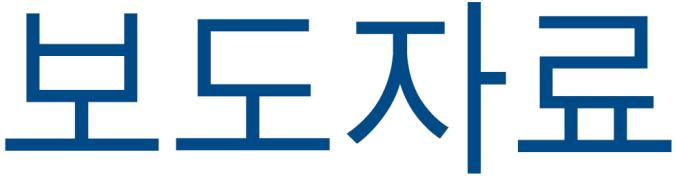

요약: “보도자료”라는 텍스트가 포함된 이미지.

[2] figure-1-2.jpg


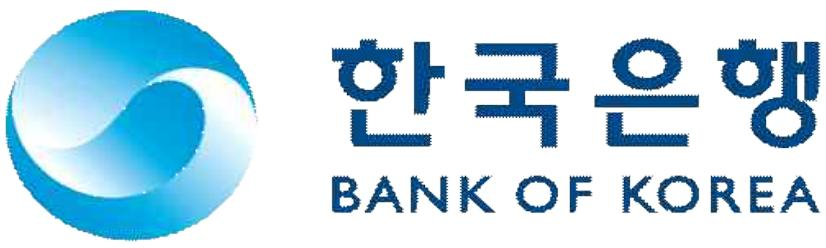

요약: 한국은행 로고: 파란색과 흰색의 둥근 심볼과 한글, 영어로 '한국은행' 및 'BANK OF KOREA' 표기.

[3] figure-10-20.jpg


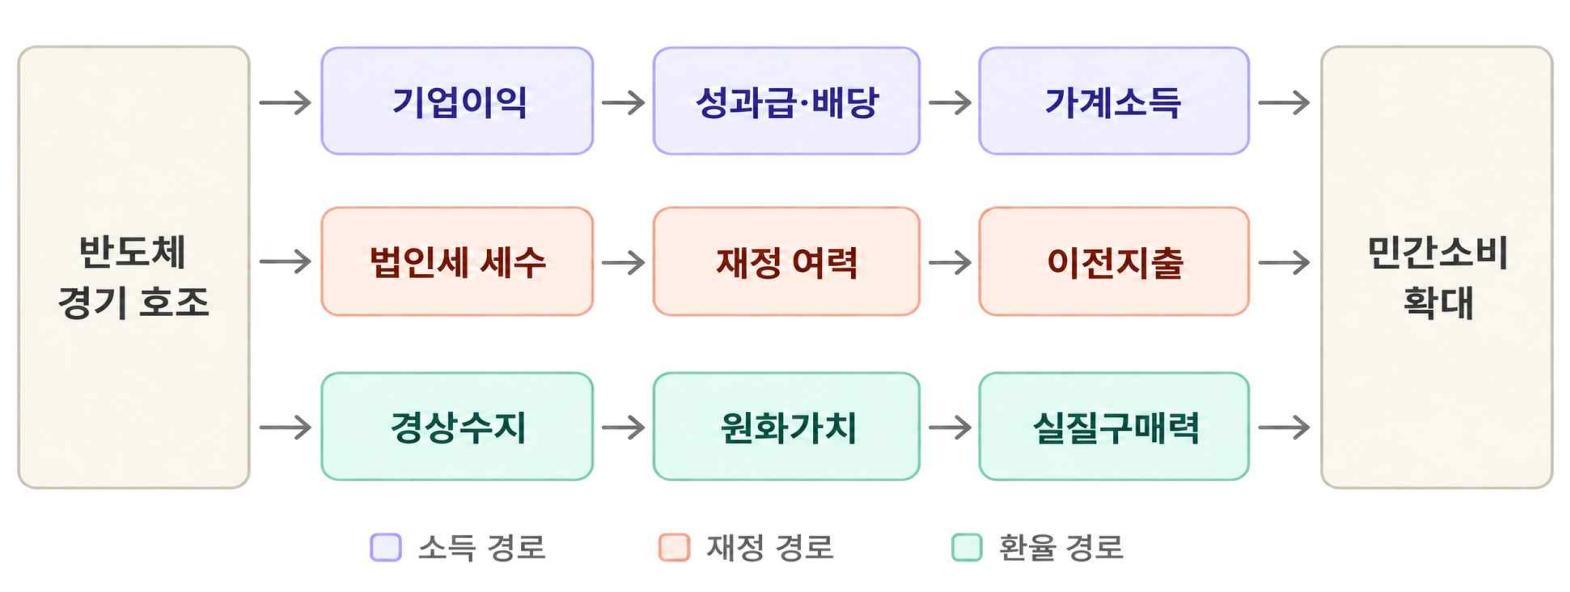

요약: 반도체 경기 호조와 관련된 다양한 경제 요소들을 나타내는 다이어그램. 주요 경로는 기업 이익, 성과 급배당, 가계 소득, 법인세 세수, 재정 여력, 이전 지출, 경상수지, 원화 가치, 실질 구매력 등으로 연결되어 있으며, 전체적으로 민간 소비 확대로 이어지는 구조를 시각화함.

[4] figure-10-21.jpg


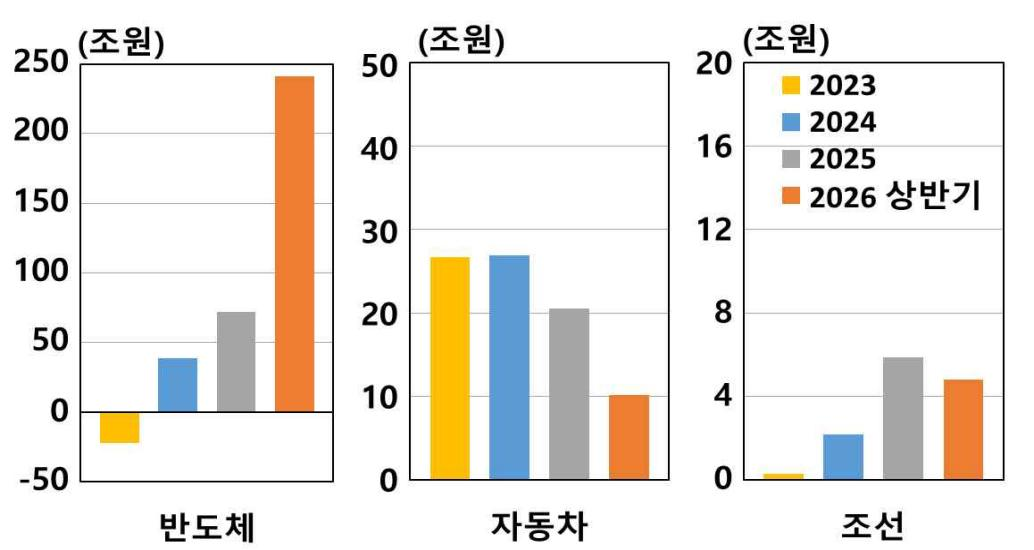

요약: 세 개의 막대그래프가 포함된 이미지. 첫 번째 그래프(반도체)는 2023년에서 2026년 상반기까지 반도체 시장 규모 변화를 보여주며, 2026년 상반기에 가장 높은 수치인 약 200조 원. 두 번째 그래프(자동차)는 자동차 시장의 추세를 나타내며, 2023년과 2024년이 비슷한 수치, 이어서 2025년과 2026년은 감소세. 마지막 그래프(조선)는 2023년부터 2026년까지의 조선 산업 규모를 보여주고, 전반적으로 낮은 수치 변동을 보임. 각 그래프에 연도별 구분색상이 포함됨.

[5] figure-10-22.jpg


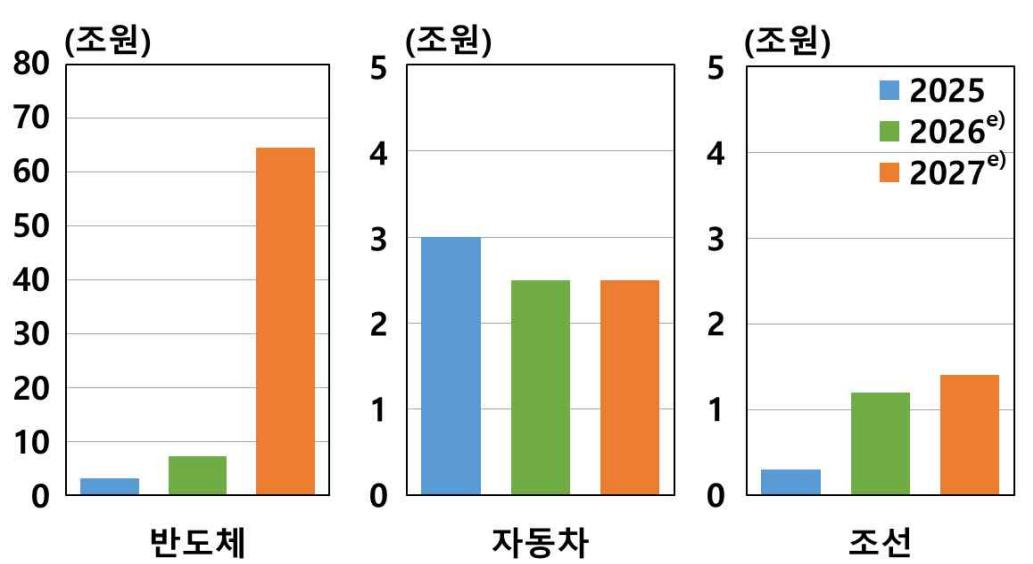

요약: 막대그래프 3개가 있는 이미지로, 각 그래프는 "반도체", "자동차", "조선" 산업의 예측 데이터를 보여줌. 그래프는 2025, 2026, 2027년의 예상치를 비교하며, 반도체는 2027년에 최저 60 조원을 넘는 큰 숫자를 나타내고, 자동차와 조선은 상대적으로 낮은 수치를 기록. 데이터는 연도별로 색상으로 구분됨.



In [23]:
for i, (img_file, summary) in enumerate(zip(img_files[:5], img_summaries[:5])):
    print("="*60)
    print(f"[{i+1}] {img_file.name}")
    print("="*60)
    display(Image(filename=str(img_file), width=450))
    print(f"요약: {summary}")
    print()

In [24]:
enc = tiktoken.encoding_for_model("gpt-4o-mini")
input_tokens = sum(len(enc.encode(t)) for t in texts_2k_token)
output_tokens = sum(len(enc.encode(s)) for s in text_summaries)

print("="*60)
print(f"입력: {input_tokens}")
print(f"출력: {output_tokens}")
print(f"합계 토큰(천 단위 콤마): {input_tokens+output_tokens:,} 토큰")
print()
print(f"요약한 이미지 수: {len(img_summaries)} 장")
print("="*60)
print()

입력: 13849
출력: 5320
합계 토큰(천 단위 콤마): 19,169 토큰

요약한 이미지 수: 41 장



In [25]:
vectorstore = Chroma(
    collection_name="multimodal_rag",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small")
)
store = InMemoryStore()
id_key = "doc_id"
retriever = MultiVectorRetriever(vectorstore=vectorstore, docstore=store, id_key=id_key)

print("검색기 생성 완료")

검색기 생성 완료


In [26]:
def add_documents(retriever, doc_summaries, doc_contents):
    """요약본은 벡터 DB에, 원본은 docstore에 '같은 id'로 저장합니다."""
    doc_ids = [str(uuid.uuid4()) for _ in doc_contents]
    summary_docs = [
        _Doc(page_content=s, metadata={id_key: doc_ids[i]})
        for i, s in enumerate(doc_summaries)
    ]

    vectorstore = retriever.vectorstore.add_documents(summary_docs)
    store = retriever.docstore.mset(list(zip(doc_ids, doc_contents)))

if text_summaries:
    add_documents(retriever, text_summaries, texts_2k_token)
if table_summaries:
    add_documents(retriever, table_summaries, tables)
if img_summaries:
    add_documents(retriever, img_summaries, img_base64_list)

print("색인 완료")
print(len(vectorstore.get()["ids"]))

색인 완료
64


In [27]:
query = "그래프에 나타난 국제유가 및 경유 가격에 대해 설명해줘"
found = retriever.invoke(query)

print(f"검색된 원본 수: {len(found)}")

for i, doc in enumerate(found):
    content = doc.page_content if hasattr(doc, "page_content") else doc
    is_img = bool(re.match("^[A-Za-z0-9+/]{100,}={0,2}$", content))
    # Base64에 쓰는 문자만 100개 이상 이어지고, 끝에 = 이 0~2개 붙은 문자열은 이미지다.
    kind = "이미지(Base64)" if is_img else "텍스트/표"
    print(f"[{i}] {kind} - 길이: {len(content):,}자")
    print("   ", content[:120].replace('\n', ' '), "...")
    print()

검색된 원본 수: 4
[0] 이미지(Base64) - 길이: 99,972자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[1] 이미지(Base64) - 길이: 74,144자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[2] 이미지(Base64) - 길이: 45,240자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[3] 이미지(Base64) - 길이: 108,120자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...



In [28]:
def split_image_text_types(docs):
    """검색 결과를 Base64 이미지와 텍스트로 나눕니다."""
    b64_img = []
    texts_out = []

    for doc in docs:
        content = doc.page_content if isinstance(doc, _Doc) else doc
        if re.match("^[A-Za-z0-9+/]{100,}={0,2}$", content):
            b64_img.append(content)
        else:
            texts_out.append(content)

    return {"images": b64_img, "texts": texts_out}

split_data = split_image_text_types(found)
print(f"이미지: {len(split_data['images'])}")
print(f"텍스트: {len(split_data['texts'])}")

이미지: 4
텍스트: 0


In [29]:
def img_prompt_func(data_dict):
    """검색된 원본을 멀티모달 LLM이 읽을 형태로 조립합니다."""
    messages = []

    for img in data_dict["context"]["images"]:
        messages.append(
            {"type": "image_url",
             "image_url": {"url": f"data:image/jpg;base64,{img}"}}
        )
    formatted_texts = "\n".join(data_dict["context"]["texts"])
    messages.append({
        "type": "text",
        "text": ("자료를 근거로 질문에 한국어로 답하세요.\n"
        "자료에 없는 내용은 모른다고 답하세요.\n\n"
        f"질문: {data_dict['question']}\n\n"
        f"참고 텍스트:\n {formatted_texts}")
    })

    return [HumanMessage(content=messages)]

model = ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)

chain = ({"context": retriever | RunnableLambda(split_image_text_types),
          "question": RunnablePassthrough()}
          | RunnableLambda(img_prompt_func)
          | model
          | StrOutputParser()
)

print("최종 체인 조립 완료")

최종 체인 조립 완료


In [30]:
start = time.time()
answer = chain.invoke(query)

print(f"소요 시간: {time.time() - start:.1f}초\n")
print(f"질문: {query}")
print("="*60)
print(answer)

소요 시간: 6.8초

질문: 그래프에 나타난 국제유가 및 경유 가격에 대해 설명해줘
첫 번째 그래프는 국제유가와 경유 가격의 변화를 보여줍니다. 두바이유와 브렌트유, 그리고 국제경유의 가격이 시간에 따라 어떻게 변동했는지를 나타내고 있습니다. 

- **두바이유**: 그래프에서 파란색 선으로 표시되어 있으며, 가격이 비교적 안정적인 흐름을 보이다가 특정 시점에서 급격한 상승을 경험했습니다.
- **브렌트유**: 빨간색 선으로 표시되어 있으며, 두바이유와 유사한 패턴을 보이지만 약간의 차이를 보입니다.
- **국제경유**: 분홍색 선으로 표시되어 있으며, 두바이유와 브렌트유의 가격 변동과 유사한 경향을 보입니다.

전반적으로, 이 그래프는 국제유가와 경유 가격이 특정 시점에서 급등했음을 보여주며, 이는 글로벌 경제 상황이나 공급망 문제 등 다양한 요인에 의해 영향을 받을 수 있습니다.


In [31]:
textstore = Chroma(collection_name="text_only_rag", embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"))
textstore.add_texts(texts=texts_2k_token)
text_retriever = textstore.as_retriever(search_kwargs={"k": 4})
text_prompt = ChatPromptTemplate.from_template(
    "자료를 근거로 질문에 한국어로 답하세요.\n" \
    "자료에 없는 내용은 모른다고 답하세요.\n\n" \
    "참고 텍스트: {context}\n\n" \
    "질문: {question}"
)

text_chain = ({"context": text_retriever | RunnableLambda(lambda docs: "\n".join(d.page_content for d in docs)),
               "question": RunnablePassthrough()}
               | text_prompt | model | StrOutputParser())

print("비교용 텍스트 전용 RAG 준비 완료")

비교용 텍스트 전용 RAG 준비 완료


In [32]:
print("="*60)
print(f"질문: {query}")
print("="*60)
print("[BEFORE] 텍스트 전용 RAG")
before = text_chain.invoke(query)
print(before)
print()
print("="*60)
print("[AFTER] 멀티모달 RAG")
after = chain.invoke(query)
print(after)
print()

질문: 그래프에 나타난 국제유가 및 경유 가격에 대해 설명해줘
[BEFORE] 텍스트 전용 RAG
자료에 국제유가 및 경유 가격에 대한 그래프나 구체적인 내용이 포함되어 있지 않으므로, 이에 대한 설명은 할 수 없습니다.

[AFTER] 멀티모달 RAG
첫 번째 그래프는 국제유가와 경유 가격의 변화를 보여줍니다. 그래프에서 두바이유, 브렌트유, 그리고 국제경유의 가격이 시간에 따라 어떻게 변했는지를 나타내고 있습니다. 

- 두바이유와 브렌트유는 상대적으로 비슷한 가격 변동을 보이며, 특정 시점에서 급격한 상승이 나타났습니다.
- 국제경유 가격도 비슷한 패턴을 보이며, 전체적으로 상승세를 보이다가 다시 하락하는 경향이 있습니다.

이러한 가격 변동은 국제적인 원유 수급 상황, 정치적 요인, 경제적 변화 등 다양한 요인에 의해 영향을 받을 수 있습니다.



In [33]:
query_list = [
    "2026년 상반기에 영업이익이 급증한 업종은 무엇인가요?",
    "일시소득의 평균 한계소비성향은 얼마인가요?",
    "환율 하락으로 구매력이 가장 많이 개선되는 소득분위는 어디인가요?",
    "증시 조정 이후 소비가 가장 크게 줄어든 품목은 무엇인가요?",
    "저소득층에 영향이 가장 큰 요인은 무엇인가요?"
]

for i, q in enumerate(query_list):
    print("="*60)
    print(f"질문{i+1}: {q}")
    print("="*60)
    print(f"답변: {chain.invoke(q)}")

질문1: 2026년 상반기에 영업이익이 급증한 업종은 무엇인가요?
답변: 자료에 따르면 2026년 상반기에 영업이익이 급증한 업종에 대한 구체적인 정보는 제공되지 않았습니다. 따라서 이 질문에 대한 답변은 모릅니다.
질문2: 일시소득의 평균 한계소비성향은 얼마인가요?
답변: 자료에 따르면, 일시소득의 평균 한계소비성향(MPC)은 약 11%입니다. 즉, 일시소득이 100만원 증가할 때 약 11만원이 소비로 이어진다고 추정됩니다.
질문3: 환율 하락으로 구매력이 가장 많이 개선되는 소득분위는 어디인가요?
답변: 환율 하락으로 구매력이 가장 많이 개선되는 소득분위는 1분위입니다. 1분위의 구매력 개선폭은 0.46%로, 5분위의 0.20%보다 두 배 이상 높습니다.
질문4: 증시 조정 이후 소비가 가장 크게 줄어든 품목은 무엇인가요?
답변: 자료에 따르면 증시 조정 이후 소비가 가장 크게 줄어든 품목은 백화점 소매판매와 여가서비스 등 주가변동에 민감한 품목입니다.
질문5: 저소득층에 영향이 가장 큰 요인은 무엇인가요?
답변: 저소득층에 영향이 가장 큰 요인은 "환율 하락"입니다. 환율 하락은 수입물가 하락을 통해 가계 전반의 실질구매력을 높이고, 특히 저소득층의 소비여력 개선에 기여할 것으로 예상됩니다.
